# 营销触达的因果效应与客户投放策略

**业务决策：** 当只能联系约 20% 的候选客户时，如何根据客户特征分配营销名额，以获得更多新增购买？本文件先检查数据与研究设计，为后续模型和策略评价提供依据。

**本文件的关键发现：** 触达组购买率高出 3.32 个百分点；已观测特征最大绝对 SMD 为 0.0073。前者是组间差异，后者是平衡诊断，都不能单独证明随机分配。

**数据处理重点：** 将商品明细汇总为交易，防止整笔金额重复累加；保留异常年龄客户并处理其年龄值；排除可能包含截止点后信息的首次兑换日期。

**版本与阅读说明：** 2026-10-25 补充固定客户划分清单及恢复逻辑。原始数据与运行环境已具备，本文件可从原始数据和 `data/splits/` 重建处理后数据。完整概览见 [README](README.md)，复现方法见 [运行说明](docs/reproducibility.md)。


## 1. 研究问题

本项目研究营销短信触达是否提高客户购买概率，以及在触达名额有限时，如何选择客户以获得更多增量购买。

分析分为三个层次：

1. **平均效果**：触达组与对照组的购买率相差多少？在因果识别假设成立时，这一差异能否解释为平均处理效应？
2. **效果异质性**：不同客户的预期触达效果是否不同？
3. **策略价值**：在相同触达名额下，按预测增量效果选择客户，是否优于按购买概率、RFM 或随机选择客户？

主要策略评价场景设定为触达约 20% 的候选客户。该比例是本项目设定的容量约束，不代表已验证的最优预算。

## 2. 数据与变量定义

本项目使用 RetailHero 营销触达数据，以客户为分析单位。

| 项目 | 本项目中的定义 |
|---|---|
| 分析样本 | `uplift_train.csv` 中的 200,039 名有标签客户 |
| 处理变量 T | `treatment_flg`，表示是否发生营销触达；其具体记录口径仍需进一步核实 |
| 结果变量 Y | `target`，表示触达后的购买情况；具体观察窗口仍需进一步核实 |
| 客户特征 X | 年龄、性别，以及由触达前交易历史构造的行为特征 |
| 特征统计截止点 | 本项目设定为 2019-03-19 00:00:00；该日期不直接等同于已确认的处理发生时间 |
| 适用人群 | 当前样本中的近期活跃客户，不直接外推至沉睡客户或全部零售客户 |

官方数据说明将 `purchases.csv` 定义为触达前的购买历史，将 `target` 定义为触达后的购买结果。

来源：https://ods.ai/competitions/x5-retailhero-uplift-modeling/data

## 3. 估计目标

设 Y(1) 表示客户受到触达时的潜在购买结果，Y(0) 表示未受到触达时的潜在购买结果。

**平均处理效应：**

$$
ATE = E[Y(1)-Y(0)]
$$

**条件平均处理效应：**

$$
\tau(x)=E[Y(1)-Y(0)\mid X=x]
$$

它表示具有相应特征的客户群体的平均效果，不是可以直接观测的个人真实效果。

**策略相对不触达的增量价值：**

$$
G(\pi)=E[\pi(X)\{Y(1)-Y(0)\}]
$$

其中，π 表示客户选择策略。对于确定性策略，被选中的客户取值为 1，其余客户取值为 0；对于随机策略，π 可以表示触达概率。

本项目报告 `1000 × G(π)`，即每 1,000 名候选客户相对完全不触达预计增加的购买人数。分母是全部候选客户，而非仅被选中的客户。

## 4. 数据来源、识别依据与研究限制

### 4.1 数据来源与业务背景

本项目使用 X5 RetailHero 营销触达数据。官方任务说明指出，零售商通过短信鼓励客户购买，研究目标是识别因触达而增加购买可能性的客户，以提高有限营销资源的使用效率。[官方任务说明](https://ods.ai/competitions/x5-retailhero-uplift-modeling)

官方数据说明明确：

- `treatment_flg` 表示是否发生营销沟通。
- `target` 表示沟通后的购买情况。
- `purchases.csv` 提供沟通前的购买历史。
- `clients.csv` 提供客户基本资料。

因此，使用购买历史构造处理前行为特征具有来源依据，但不能据此认定客户资料表中的全部字段都只包含处理前信息。[官方数据说明](https://ods.ai/competitions/x5-retailhero-uplift-modeling/data)

### 4.2 处理概率与因果识别

scikit-uplift 的数据文档记载，该数据包含 200,039 名有标签客户，处理比例约为 0.5，与本项目的数据检查结果一致。但该比例本身不能证明处理随机分配，也不能证明所有客户的条件处理概率均为 0.5。[scikit-uplift 数据文档](https://www.uplift-modeling.com/en/latest/api/datasets/fetch_x5.html)

本项目采用 `e = 0.5` 进行 DR 和 IPW 评价，将其保留为分析假设，而非已经核实的实验设计事实。效果估计的因果解释需要处理分配具有可比性，以及处理定义一致、没有重要客户间干扰等条件。若实际分配依赖客户特征，恒定处理概率可能不适用；若存在未观测混杂，当前方法不能自动消除其影响。

特征平衡检查可以描述已观测变量的组间差异，但不能替代随机分配或无未观测混杂的识别依据。

### 4.3 时间口径与特征使用

本项目根据所提供交易记录的范围，将 `2019-03-19 00:00:00` 设为特征统计截止点。该日期是项目中的计算设定，不直接等同于已确认的短信发送日期。

客户日期审计发现，部分首次兑换日期位于截止点及之后，另有缺失及日期顺序异常记录。因此，当前模型不使用首次兑换日期及其衍生特征。

在已查阅的资料中，尚未确认具体短信发送日期、每位客户的结果观察窗口，以及 `treatment_flg` 区分的是发送安排、实际发送还是成功送达。报告不将结果解释为特定天数内的购买提升，也不将其直接称为成功送达或实际阅读短信的效果。

### 4.4 本项目的评价设定与适用范围

本项目将触达约 20% 的候选客户作为容量约束，用于比较不同客户选择策略。这是本项目的业务情景设定，并非经过验证的最优预算。原竞赛使用排名前 30% 的客户评价平均增量转化，因此本项目结果不直接作为原竞赛指标报告。[官方评价说明](https://ods.ai/competitions/x5-retailhero-uplift-modeling)

本项目自行从有标签样本中划分训练、验证和测试集；这里的测试集不是官方无标签的 `uplift_test.csv`。测试结果此前已查看，后来新增的比较作为探索性分析报告。

分析样本均为本数据中的近期活跃客户，结论首先适用于这一人群。最终结果表述为：在所列处理概率及因果识别假设成立的条件下，对营销触达效果和客户选择策略增量收益的离线估计，不代表已验证的线上收益或利润。

## 5. 分析流程

1. 检查数据质量与时间口径，构建客户级特征。
2. 检查处理前特征平衡，估计两组购买率差异。
3. 划分训练、验证和测试数据，拟合购买概率与 uplift 模型。
4. 在验证阶段比较策略、检查效果异质性与校准。
5. 对固定方案进行测试评价，并报告识别限制和业务适用范围。

运行说明：在项目根目录使用项目 Python 环境，按 01 → 02 → 03 执行。01 读取 data/raw/ 和 data/splits/，无需预先存在 data/processed/。保留原客户名单和顺序，不重新抽样。


## 6. 数据读取与质量检查


In [ ]:
from pathlib import Path
import pandas as pd

DATA = Path("data/raw")

print("从项目 data/raw 目录读取原始数据")

clients = pd.read_csv(DATA / "clients.csv.gz")
train = pd.read_csv(DATA / "uplift_train.csv.gz")

print("客户表行列数：", clients.shape)
print("训练表行列数：", train.shape)
print("客户表字段：", clients.columns.tolist())
print("训练表字段：", train.columns.tolist())

### 6.1 客户 ID 与标签检查


In [2]:
# 检查处理变量和结果变量的取值、数量
pd.crosstab(
    train["treatment_flg"],
    train["target"],
    margins=True
)

target,0,1,All
treatment_flg,,,
0,39695,60363,100058
1,36342,63639,99981
All,76037,124002,200039


In [3]:
import duckdb

con = duckdb.connect()

con.register("clients_raw", clients)
con.register("train_raw", train)

In [4]:
id_checks = con.sql("""
    SELECT
        'clients' AS table_name,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT client_id) AS unique_clients,
        COUNT(*) - COUNT(client_id) AS missing_ids,
        COUNT(client_id) - COUNT(DISTINCT client_id) AS duplicate_ids
    FROM clients_raw

    UNION ALL

    SELECT
        'train' AS table_name,
        COUNT(*) AS total_rows,
        COUNT(DISTINCT client_id) AS unique_clients,
        COUNT(*) - COUNT(client_id) AS missing_ids,
        COUNT(client_id) - COUNT(DISTINCT client_id) AS duplicate_ids
    FROM train_raw
""").df()

display(id_checks)

assert id_checks[["missing_ids", "duplicate_ids"]].eq(0).all().all(), "客户 ID 缺失或重复，停止运行"


,table_name,total_rows,unique_clients,missing_ids,duplicate_ids
0,clients,400162,400162,0,0
1,train,200039,200039,0,0


In [5]:
label_checks = con.sql("""
    SELECT
        COUNT(*) FILTER (
            WHERE treatment_flg IS NULL
               OR treatment_flg NOT IN (0, 1)
        ) AS invalid_treatment,

        COUNT(*) FILTER (
            WHERE target IS NULL
               OR target NOT IN (0, 1)
        ) AS invalid_target,

        COUNT(*) FILTER (
            WHERE NOT EXISTS (
                SELECT 1
                FROM clients_raw AS c
                WHERE c.client_id = t.client_id
            )
        ) AS unmatched_clients

    FROM train_raw AS t
""").df()

display(label_checks)

assert label_checks.eq(0).all().all(), "标签或客户关联失败，停止运行"


,invalid_treatment,invalid_target,unmatched_clients
0,0,0,0


### 6.2 客户日期审计


In [6]:
import pandas as pd

FEATURE_CUTOFF = pd.Timestamp("2019-03-19 00:00:00")

# 只检查参与当前分析的有标签客户
date_audit = train[["client_id"]].merge(
    clients[[
        "client_id",
        "first_issue_date",
        "first_redeem_date"
    ]],
    on="client_id",
    how="left",
    validate="one_to_one"
)

date_columns = ["first_issue_date", "first_redeem_date"]
audit_rows = []

for column in date_columns:
    raw = date_audit[column]

    # 在审计表中新增解析列，不覆盖原始字段
    parsed = pd.to_datetime(
        raw,
        errors="coerce",
        format="mixed"
    )
    date_audit[f"{column}_parsed"] = parsed

    audit_rows.append({
        "字段": column,
        "客户数": len(date_audit),
        "原始缺失数": int(raw.isna().sum()),
        "非空但解析失败数": int(
            (raw.notna() & parsed.isna()).sum()
        ),
        "截止点之前": int((parsed < FEATURE_CUTOFF).sum()),
        "截止点及之后": int((parsed >= FEATURE_CUTOFF).sum()),
        "最早日期": parsed.min(),
        "最晚日期": parsed.max()
    })

date_summary = pd.DataFrame(audit_rows)

print("特征截止点：", FEATURE_CUTOFF)
display(date_summary)

# 补查两类需要解释的记录
issue_date = date_audit["first_issue_date_parsed"]
redeem_date = date_audit["first_redeem_date_parsed"]

consistency_summary = pd.DataFrame({
    "检查项": [
        "首次兑换日期早于首次发卡日期",
        "发卡日期在截止点及之后"
    ],
    "客户数": [
        int((
            issue_date.notna()
            & redeem_date.notna()
            & (redeem_date < issue_date)
        ).sum()),
        int((issue_date >= FEATURE_CUTOFF).sum())
    ]
})

display(consistency_summary)

特征截止点： 2019-03-19 00:00:00


,字段,客户数,原始缺失数,非空但解析失败数,截止点之前,截止点及之后,最早日期,最晚日期
0,first_issue_date,200039,0,0,200039,0,2017-04-04 18:24:18,2019-03-15 21:44:14
1,first_redeem_date,200039,17546,0,159893,22600,2017-04-11 09:42:20,2019-11-20 01:14:10


,检查项,客户数
0,首次兑换日期早于首次发卡日期,245
1,发卡日期在截止点及之后,0


### 客户日期审计结论与处理规则

以本项目设定的特征截止点 `2019-03-19 00:00:00` 为界，对 200,039 名有标签客户进行检查：

- `first_issue_date` 无缺失和解析失败，全部早于截止点。
- `first_redeem_date` 有 17,546 条缺失，非空记录均可成功解析。
- 22,600 名客户的首次兑换日期位于截止点及之后，说明该客户资料表包含不能直接用于构造处理前特征的信息。
- 245 名客户的首次兑换日期早于首次发卡日期，需要进一步核实字段定义及记录质量。

据此采用以下规则：

1. **保留全部客户。** 不因兑换日期缺失、晚于截止点或日期顺序异常而直接删除客户，避免不必要地改变研究人群。
2. **当前模型继续排除首次兑换日期及其衍生特征。** 不使用全表日期是否非空构造“历史上是否兑换过”，也不计算可能利用截止点之后信息的兑换时长。
3. **保留原始日期。** 若后续引入兑换特征，需先核实缺失含义、日期定义，以及是否能够可靠重建截止点之前的信息状态。
4. **会员存续时长作为候选特征。** 发卡日期通过本次时间检查，但是否加入模型，应在确认其处理前可用性后，通过验证集评价决定。

本次检查仅验证日期与所设特征截止点的关系，不能单独证明所有特征均早于真实处理时间。真实处理时间和结果观察窗口仍待来源资料核实。

### 6.3 客户级分析表与人口属性


In [7]:
con.execute("""
    CREATE OR REPLACE TEMP VIEW analysis_base AS
    SELECT
        t.client_id,
        t.treatment_flg,
        t.target,
        c.age,
        c.gender,
        c.first_issue_date,
        c.first_redeem_date
    FROM train_raw AS t
    LEFT JOIN clients_raw AS c
        ON t.client_id = c.client_id
""")

analysis = con.sql("SELECT * FROM analysis_base").df()

print("分析表行列数：", analysis.shape)
analysis.head()

分析表行列数： (200039, 7)


,client_id,treatment_flg,target,age,gender,first_issue_date,first_redeem_date
0,c4c224ced6,1,1,69,F,2017-09-12 10:21:22,2018-11-23 18:39:45
1,c4c2a43212,0,0,18,U,2018-10-07 22:14:52,NaN
2,c4c2af3035,1,0,83,F,2018-12-18 14:02:23,NaN
3,c4c31cd238,0,1,115,M,2019-01-15 19:41:58,2019-02-01 14:10:42
4,c4c3a33790,1,1,62,F,2017-04-17 14:00:01,2017-12-26 19:27:40


In [8]:
# 各字段的缺失情况
missing_summary = pd.DataFrame({
    "missing_count": analysis.isna().sum(),
    "missing_pct": analysis.isna().mean().mul(100).round(2)
})

display(missing_summary)

# 年龄基本情况
display(con.sql("""
    SELECT
        MIN(age) AS min_age,
        MAX(age) AS max_age,
        AVG(age) AS mean_age,
        COUNT(*) FILTER (
            WHERE age < 0 OR age > 110
        ) AS age_review_count
    FROM analysis_base
""").df())

# 性别的实际编码与人数
display(con.sql("""
    SELECT gender, COUNT(*) AS customers
    FROM analysis_base
    GROUP BY gender
    ORDER BY customers DESC
""").df())

,missing_count,missing_pct
client_id,0,0.00
treatment_flg,0,0.00
target,0,0.00
age,0,0.00
gender,0,0.00
first_issue_date,0,0.00
first_redeem_date,17546,8.77


,min_age,max_age,mean_age,age_review_count
0,-7491,1852,46.417329,570


,gender,customers
0,U,92832
1,F,73696
2,M,33511


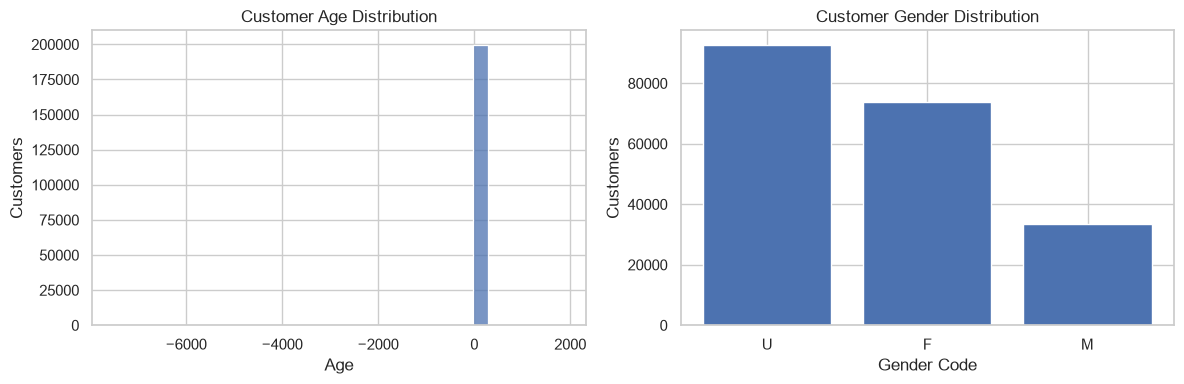

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=analysis,
    x="age",
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Customers")

gender_counts = (
    analysis["gender"]
    .fillna("Missing")
    .value_counts()
)

axes[1].bar(
    gender_counts.index.astype(str),
    gender_counts.values
)
axes[1].set_title("Customer Gender Distribution")
axes[1].set_xlabel("Gender Code")
axes[1].set_ylabel("Customers")

plt.tight_layout()
plt.show()

数据质量问题：
| 发现 | 解读与处理 |
|---|---|
| 年龄从 −7491 到 1852，570 条超出之前设定的 0–110 范围，约占 **0.28%** | 保留客户，将这些年龄标记为待复核，并在清洗后的年龄列中设为缺失 |
| `gender="U"` 有 92,832 人，约占 **46.41%** | 保留为独立类别，具体含义待数据字典确认 |
| `first_redeem_date` 缺失 **8.77%** | 缺失原因待确认，不能直接解释成“从未兑换” |

### 6.4 年龄清洗


In [10]:
con.execute("""
    CREATE OR REPLACE TEMP VIEW analysis_clean AS
    SELECT
        client_id,
        treatment_flg,
        target,

        age AS age_raw,

        CASE
            WHEN age BETWEEN 0 AND 110 THEN age
            ELSE NULL
        END AS age_clean,

        CASE
            WHEN age IS NULL OR age < 0 OR age > 110 THEN 1
            ELSE 0
        END AS age_review_flag,

        gender,
        first_issue_date,
        first_redeem_date

    FROM analysis_base
""")

clean = con.sql("SELECT * FROM analysis_clean").df()

In [11]:
con.sql("""
    SELECT
        COUNT(*) AS total_customers,
        SUM(age_review_flag) AS flagged_age_count,
        COUNT(*) FILTER (
            WHERE age_clean IS NULL
        ) AS missing_clean_age,
        MIN(age_clean) AS min_clean_age,
        MAX(age_clean) AS max_clean_age,
        AVG(age_clean) AS mean_clean_age
    FROM analysis_clean
""").df()

,total_customers,flagged_age_count,missing_clean_age,min_clean_age,max_clean_age,mean_clean_age
0,200039,570.0,570,0,109,46.365561


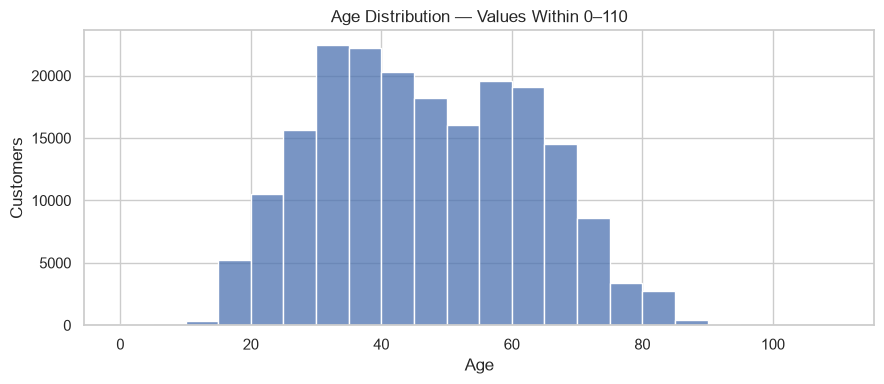

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))

sns.histplot(
    data=clean,
    x="age_clean",
    bins=22,
    binrange=(0, 110),
    ax=ax
)

ax.set_title("Age Distribution — Values Within 0–110")
ax.set_xlabel("Age")
ax.set_ylabel("Customers")

plt.tight_layout()
plt.show()

年龄直方图仅展示满足 0–110 岁暂定规则的记录。570 位年龄异常客户仍保留在分析表中，原始年龄与复核标记均予以保留。


## 7. 两组购买率差异


In [13]:
experiment_summary = con.sql("""
    SELECT
        treatment_flg,
        COUNT(*) AS customers,
        SUM(target) AS purchasers,
        AVG(CAST(target AS DOUBLE)) AS purchase_rate
    FROM analysis_clean
    GROUP BY treatment_flg
    ORDER BY treatment_flg
""").df().set_index("treatment_flg")

display(experiment_summary)

,customers,purchasers,purchase_rate
treatment_flg,,,
0,100058,60363.0,0.603280
1,99981,63639.0,0.636511


② 用 Python 计算差异、置信区间和检验结果
这里使用大样本正态近似，假设客户之间独立。置信区间使用两组各自的方差；双侧检验在“购买率相等”的原假设下使用合并购买率。

In [14]:
from math import sqrt, erfc
from statistics import NormalDist

n0 = experiment_summary.loc[0, "customers"]
n1 = experiment_summary.loc[1, "customers"]

p0 = experiment_summary.loc[0, "purchase_rate"]
p1 = experiment_summary.loc[1, "purchase_rate"]

# 购买率差异及 95% 置信区间
difference = p1 - p0

se = sqrt(
    p0 * (1 - p0) / n0
    + p1 * (1 - p1) / n1
)

critical_value = NormalDist().inv_cdf(0.975)

ci_low = difference - critical_value * se
ci_high = difference + critical_value * se

# 双侧两比例 Z 检验
pooled_rate = (n0 * p0 + n1 * p1) / (n0 + n1)

se_null = sqrt(
    pooled_rate * (1 - pooled_rate) * (1 / n0 + 1 / n1)
)

z_stat = difference / se_null
p_value = erfc(abs(z_stat) / sqrt(2))

print(f"对照组购买率：{p0:.2%}")
print(f"触达组购买率：{p1:.2%}")
print(f"购买率差异：{difference * 100:.2f} 个百分点")
print(
    f"95% 置信区间："
    f"[{ci_low * 100:.2f}, {ci_high * 100:.2f}] 个百分点"
)
print(f"双侧检验 p 值：{p_value:.2e}")

对照组购买率：60.33%
触达组购买率：63.65%
购买率差异：3.32 个百分点
95% 置信区间：[2.90, 3.75] 个百分点
双侧检验 p 值：6.62e-53


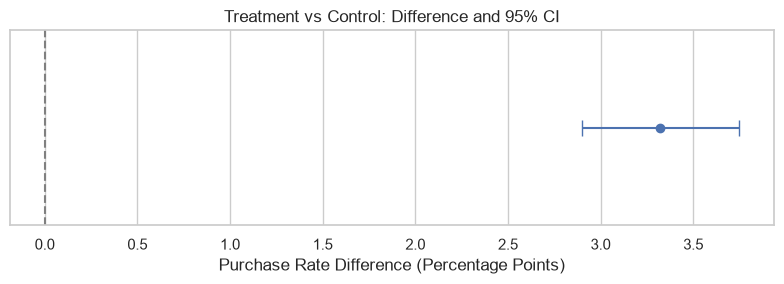

In [15]:
fig, ax = plt.subplots(figsize=(8, 3))

ax.errorbar(
    x=difference * 100,
    y=0,
    xerr=critical_value * se * 100,
    fmt="o",
    capsize=6
)

ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks([])
ax.set_xlabel("Purchase Rate Difference (Percentage Points)")
ax.set_title("Treatment vs Control: Difference and 95% CI")

plt.tight_layout()
plt.show()

### 购买率差异及其解释

对照组共有 100,058 名客户，其中 60,363 人购买，购买率为 60.33%；触达组共有 99,981 名客户，其中 63,639 人购买，购买率为 63.65%。

触达组购买率比对照组高 **3.32 个百分点**，基于客户间独立的大样本近似，95% 置信区间为 **[2.90, 3.75] 个百分点**。双侧两比例 Z 检验的 p 值约为 `6.62 × 10⁻⁵³`，表明在该检验假设下，两组购买率存在统计差异。

需要区分以下解释：

- **描述性结论：** 当前样本中，触达组的购买率高于对照组。
- **因果解释：** 若处理确实随机分配，且处理定义一致、没有重要客户间干扰或破坏可比性的样本筛选等问题，则该差异可用于估计相应研究人群的平均处理效应。目前处理分配机制仍待核实，因此保留条件化表述。

在上述因果解释成立时，3.32 个百分点相当于：对每 1,000 名同类客户全部实施触达，相对全部不触达，平均约增加 33.2 名购买客户。它不是固定触达 20% 客户的策略收益，也不直接表示利润增加。

本节衡量总体平均差异，不能据此判断每位客户是否受益，也不能证明按 uplift 排序优于其他客户选择策略。后续需通过独立的策略评价回答这些问题。

## 8. 交易审计与行为特征


### 8.1 交易明细结构与完整性


In [16]:
# 创建购买明细视图，后续可以直接用 SQL 查询
con.execute("""
    CREATE OR REPLACE TEMP VIEW purchases_raw AS
    SELECT *
    FROM read_csv_auto('data/raw/purchases.csv.gz')
""")

# 查看字段及推断的数据类型
purchase_schema = con.sql("""
    DESCRIBE purchases_raw
""").df()

display(purchase_schema)

,column_name,column_type,null,key,default,extra
0,client_id,VARCHAR,YES,None,None,None
1,transaction_id,VARCHAR,YES,None,None,None
2,transaction_datetime,TIMESTAMP,YES,None,None,None
3,regular_points_received,DOUBLE,YES,None,None,None
4,express_points_received,DOUBLE,YES,None,None,None
5,regular_points_spent,DOUBLE,YES,None,None,None
6,express_points_spent,DOUBLE,YES,None,None,None
7,purchase_sum,DOUBLE,YES,None,None,None
8,store_id,VARCHAR,YES,None,None,None
9,product_id,VARCHAR,YES,None,None,None


In [17]:
# 只取少量样例查看
purchase_sample = con.sql("""
    SELECT *
    FROM purchases_raw
    LIMIT 5
""").df()

display(purchase_sample)

,client_id,transaction_id,transaction_datetime,regular_points_received,express_points_received,regular_points_spent,express_points_spent,purchase_sum,store_id,product_id,product_quantity,trn_sum_from_iss,trn_sum_from_red
0,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,9a80204f78,2.0,80.0,NaN
1,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,da89ebd374,1.0,65.0,NaN
2,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,0a95e1151d,1.0,24.0,NaN
3,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,4055b15e4a,2.0,50.0,NaN
4,000012768d,7e3e2e3984,2018-12-01 07:12:45,10.0,0.0,0.0,0.0,1007.0,54a4a11a29,a685f1916b,1.0,22.0,NaN


In [18]:
purchase_overview = con.sql("""
    SELECT
        COUNT(*) AS detail_rows,
        COUNT(DISTINCT client_id) AS unique_clients,
        MIN(transaction_datetime) AS earliest_time,
        MAX(transaction_datetime) AS latest_time,

        COUNT(*) FILTER (
            WHERE client_id IS NULL
        ) AS missing_client_rows,

        COUNT(*) FILTER (
            WHERE transaction_id IS NULL
        ) AS missing_transaction_rows,

        COUNT(*) FILTER (
            WHERE transaction_datetime IS NULL
        ) AS missing_time_rows

    FROM purchases_raw
""").df()

display(purchase_overview)

assert purchase_overview[["missing_client_rows", "missing_transaction_rows", "missing_time_rows"]].eq(0).all().all(), "交易键或时间缺失"


,detail_rows,unique_clients,earliest_time,latest_time,missing_client_rows,missing_transaction_rows,missing_time_rows
0,45786568,400162,2018-11-21 21:02:33,2019-03-18 23:40:03,0,0,0


In [19]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE transaction_audit AS
    SELECT
        client_id,
        transaction_id,

        COUNT(*) AS detail_rows,
        COUNT(DISTINCT transaction_datetime) AS time_versions,
        COUNT(DISTINCT store_id) AS store_versions,
        COUNT(DISTINCT purchase_sum) AS amount_versions,

        COUNT(*) FILTER (
            WHERE purchase_sum IS NULL
        ) AS missing_amount_rows,

        MIN(purchase_sum) AS min_amount,
        MAX(purchase_sum) AS max_amount

    FROM purchases_raw
    GROUP BY client_id, transaction_id
""")

In [20]:
transaction_checks = con.sql("""
    SELECT
        COUNT(*) AS candidate_transaction_groups,

        COUNT(*) FILTER (
            WHERE detail_rows > 1
        ) AS groups_with_multiple_rows,

        COUNT(*) FILTER (
            WHERE time_versions > 1
        ) AS groups_with_multiple_times,

        COUNT(*) FILTER (
            WHERE store_versions > 1
        ) AS groups_with_multiple_stores,

        COUNT(*) FILTER (
            WHERE amount_versions > 1
        ) AS groups_with_conflicting_amounts,

        COUNT(*) FILTER (
            WHERE missing_amount_rows > 0
        ) AS groups_with_missing_amounts,

        COUNT(*) FILTER (
            WHERE min_amount < 0
        ) AS groups_with_negative_amounts

    FROM transaction_audit
""").df()

display(transaction_checks)

critical_transaction_fields = ["groups_with_multiple_times", "groups_with_multiple_stores", "groups_with_conflicting_amounts", "groups_with_missing_amounts", "groups_with_negative_amounts"]
assert transaction_checks[critical_transaction_fields].eq(0).all().all(), "同笔交易信息冲突、金额缺失或负值；必须先处理，不能直接取 MAX"


,candidate_transaction_groups,groups_with_multiple_rows,groups_with_multiple_times,groups_with_multiple_stores,groups_with_conflicting_amounts,groups_with_missing_amounts,groups_with_negative_amounts
0,8045229,6977760,0,0,0,0,0


### 8.2 汇总到交易级


In [21]:
con.execute("""
    CREATE OR REPLACE TEMP TABLE transactions AS
    SELECT
        client_id,
        transaction_id,

        MIN(transaction_datetime) AS transaction_datetime,
        MAX(store_id) AS store_id,
        MAX(purchase_sum) AS transaction_amount,

        COUNT(*) AS detail_rows,

        COUNT(*) FILTER (
            WHERE transaction_datetime IS NULL
        ) AS missing_time_rows,

        COUNT(*) FILTER (
            WHERE store_id IS NULL
        ) AS missing_store_rows

    FROM purchases_raw
    GROUP BY client_id, transaction_id
""")

In [22]:
transaction_summary = con.sql("""
    SELECT
        COUNT(*) AS transaction_count,
        SUM(detail_rows) AS original_detail_rows,
        COUNT(DISTINCT client_id) AS unique_clients,

        MIN(transaction_datetime) AS earliest_time,
        MAX(transaction_datetime) AS latest_time,

        COUNT(*) FILTER (
            WHERE client_id IS NULL
               OR transaction_id IS NULL
        ) AS missing_key_groups,

        SUM(missing_time_rows) AS missing_time_rows,
        SUM(missing_store_rows) AS missing_store_rows,

        MIN(transaction_amount) AS min_transaction_amount,
        MAX(transaction_amount) AS max_transaction_amount,
        AVG(transaction_amount) AS mean_transaction_amount

    FROM transactions
""").df()

display(transaction_summary)

assert transaction_summary[["missing_key_groups", "missing_time_rows", "missing_store_rows"]].eq(0).all().all(), "交易键、时间或门店缺失"


,transaction_count,original_detail_rows,unique_clients,earliest_time,latest_time,missing_key_groups,missing_time_rows,missing_store_rows,min_transaction_amount,max_transaction_amount,mean_transaction_amount
0,8045229,45786568.0,400162,2018-11-21 21:02:33,2019-03-18 23:40:03,0,0.0,0.0,0.0,35149.04,428.128751


In [23]:
con.sql("""
    SELECT *
    FROM transactions
    WHERE client_id = '000012768d'
      AND transaction_id = '7e3e2e3984'
""").df()

,client_id,transaction_id,transaction_datetime,store_id,transaction_amount,detail_rows,missing_time_rows,missing_store_rows
0,000012768d,7e3e2e3984,2018-12-01 07:12:45,54a4a11a29,1007.0,19,0,0


### 8.3 客户级 RFM 与近期行为特征


本项目使用以下 RFM 与近 30 天行为特征：
| 特征 | 含义 |
|---|---|
| `recency_days` | 最近一次交易距统计截止日的日历天数 |
| `txn_count_history` | 已提供历史记录中的交易次数 |
| `spend_history` | 历史交易金额合计 |
| `avg_transaction_amount` | 平均每笔交易金额 |
| `txn_count_30d` | 截止日前 30 天的交易次数 |
| `spend_30d` | 截止日前 30 天的交易金额 |
| `zero_amount_txn_count` | 历史零金额交易次数 |

In [24]:
# 固定每位客户交易的累加顺序，避免并行聚合顺序引起浮点末位漂移。
con.execute("""
    CREATE OR REPLACE TEMP TABLE customer_rfm AS

    WITH params AS (
        SELECT
            TIMESTAMP '2019-03-19 00:00:00' AS feature_cutoff
    )

    SELECT
        t.client_id,
        p.feature_cutoff,

        DATE_DIFF(
            'day',
            CAST(MAX(t.transaction_datetime) AS DATE),
            CAST(p.feature_cutoff AS DATE)
        ) AS recency_days,

        COUNT(*) AS txn_count_history,

        SUM(t.transaction_amount ORDER BY t.transaction_id) AS spend_history,

        AVG(t.transaction_amount ORDER BY t.transaction_id) AS avg_transaction_amount,

        COUNT(*) FILTER (
            WHERE t.transaction_datetime
                >= p.feature_cutoff - INTERVAL '30 days'
        ) AS txn_count_30d,

        COALESCE(
            SUM(t.transaction_amount ORDER BY t.transaction_id) FILTER (
                WHERE t.transaction_datetime
                    >= p.feature_cutoff - INTERVAL '30 days'
            ),
            0
        ) AS spend_30d,

        COUNT(*) FILTER (
            WHERE t.transaction_amount = 0
        ) AS zero_amount_txn_count

    FROM transactions AS t
    CROSS JOIN params AS p

    WHERE t.transaction_datetime < p.feature_cutoff

    GROUP BY t.client_id, p.feature_cutoff
""")

这里有三个口径值得记录：
- 最近交易发生在 3 月 18 日的客户，recency_days 为 1。
- history 表示这份数据提供的观察期，不能解释为客户终身消费。
- 零金额交易暂时保留在交易次数中，并单独计数，之后根据业务含义决定是否调整。
金额求和与平均值按 transaction_id 的固定顺序聚合。金额口径不变、不额外四舍五入；此设置减少并行聚合的浮点末位差异对树分裂和客户排序的影响。


In [25]:
feature_table = con.sql("""
    SELECT
        a.*,
        f.* EXCLUDE (client_id)

    FROM analysis_clean AS a

    LEFT JOIN customer_rfm AS f
        ON a.client_id = f.client_id
""").df()

print("客户数量：", len(feature_table))
print("客户 ID 是否唯一：", feature_table["client_id"].is_unique)
print(
    "未关联到历史特征的客户数：",
    feature_table["txn_count_history"].isna().sum()
)

assert len(feature_table) == len(train), "关联改变了客户数量"
assert feature_table.client_id.is_unique and feature_table.client_id.notna().all(), "特征表客户 ID 无效"
assert feature_table.txn_count_history.notna().all(), "存在未匹配购买历史的客户，请先明确处理规则"
assert feature_table.feature_cutoff.eq(FEATURE_CUTOFF).all(), "特征截止日期不一致"


客户数量： 200039
客户 ID 是否唯一： True
未关联到历史特征的客户数： 0


In [26]:
behavior_features = [
    "recency_days",
    "txn_count_history",
    "spend_history",
    "avg_transaction_amount",
    "txn_count_30d",
    "spend_30d",
    "zero_amount_txn_count"
]

display(
    feature_table[behavior_features]
    .describe(percentiles=[0.5, 0.95, 0.99])
    .round(2)
)

,recency_days,txn_count_history,spend_history,avg_transaction_amount,txn_count_30d,spend_30d,zero_amount_txn_count
count,200039.00,200039.00,200039.00,200039.00,200039.00,200039.00,200039.00
mean,6.83,20.12,8597.52,495.78,6.11,2631.86,0.00
std,5.67,17.73,8914.60,374.55,5.55,2947.12,0.04
min,1.00,1.00,1.04,1.04,1.00,1.00,0.00
50%,5.00,15.00,6102.44,394.00,4.00,1791.00,0.00
95%,19.00,54.00,24235.25,1193.48,17.00,7812.01,0.00
99%,22.00,85.00,41865.74,1896.65,26.00,13412.68,0.00
max,23.00,320.00,504490.38,7694.00,119.00,133567.14,1.00


这 7 个特征都成功覆盖了 200,039 位客户。 分布中有几个值得记录的发现：
- 消费金额和交易次数呈右偏分布：均值高于中位数，少数客户消费或交易频次很高。极端值需要复核，暂时保留。
- 这批有标签客户全部在近 30 天有交易：recency_days 最大为 23，txn_count_30d 最小为 1。因此，后续结论首先适用于这批近期活跃客户；是否源于竞赛筛选规则，还需要来源说明。
- 零金额交易很少：均值显示 0.00 是四舍五入，最大值为 1 说明仍有客户存在此类记录。
后续沿用已保存的训练／验证／测试客户划分；预处理参数和模型仅在训练数据上拟合。

## 9. 完整特征平衡检查


我们用**标准化均值差异（SMD）**比较特征：绝对值越接近 0，组间差异越小。常用 0.1 作为参考线，但它只是经验标准，不能证明随机化或排除未观测混杂。

In [27]:
import numpy as np
import pandas as pd

# 与当前模型的数值输入保持一致
numeric_columns = [
    "age_clean",
    "age_review_flag",
    "recency_days",
    "txn_count_history",
    "spend_history",
    "avg_transaction_amount",
    "txn_count_30d",
    "spend_30d",
    "zero_amount_txn_count"
]

# 性别各类别分别转换成 0/1 指示变量
gender_indicators = pd.get_dummies(
    feature_table["gender"].fillna("Missing"),
    prefix="gender",
    dtype=int
)

balance_features = pd.concat(
    [
        feature_table[numeric_columns],
        gender_indicators
    ],
    axis=1
).astype(float)

treatment = feature_table["treatment_flg"]

assert feature_table["client_id"].is_unique
assert treatment.notna().all()
assert treatment.isin([0, 1]).all()

control_features = balance_features.loc[treatment.eq(0)]
treated_features = balance_features.loc[treatment.eq(1)]

# 两组方差平均后开根号，作为标准化尺度
pooled_sd = np.sqrt(
    (
        control_features.var(ddof=1)
        + treated_features.var(ddof=1)
    ) / 2
)

full_balance = pd.DataFrame({
    "control_n_nonmissing": control_features.count(),
    "treated_n_nonmissing": treated_features.count(),
    "control_mean": control_features.mean(),
    "treated_mean": treated_features.mean()
})

full_balance["smd"] = (
    full_balance["treated_mean"]
    - full_balance["control_mean"]
) / pooled_sd.replace(0, np.nan)

full_balance["abs_smd"] = full_balance["smd"].abs()

full_balance = full_balance.sort_values(
    "abs_smd",
    ascending=False
)

print("对照组客户数：", len(control_features))
print("处理组客户数：", len(treated_features))
print(
    "最大绝对 SMD：",
    round(full_balance["abs_smd"].max(), 4)
)

display(full_balance.round(4))

对照组客户数： 100058
处理组客户数： 99981
最大绝对 SMD： 0.0073


,control_n_nonmissing,treated_n_nonmissing,control_mean,treated_mean,smd,abs_smd
txn_count_history,100058,99981,20.0561,20.1856,0.0073,0.0073
zero_amount_txn_count,100058,99981,0.0014,0.0017,0.0066,0.0066
spend_history,100058,99981,8569.3661,8625.6995,0.0063,0.0063
avg_transaction_amount,100058,99981,494.7630,496.8042,0.0054,0.0054
age_clean,99775,99694,46.3248,46.4064,0.0051,0.0051
txn_count_30d,100058,99981,6.1034,6.1259,0.0041,0.0041
gender_F,100058,99981,0.3676,0.3692,0.0032,0.0032
spend_30d,100058,99981,2628.1927,2635.5390,0.0025,0.0025
gender_U,100058,99981,0.4646,0.4635,-0.0021,0.0021
gender_M,100058,99981,0.1678,0.1673,-0.0013,0.0013


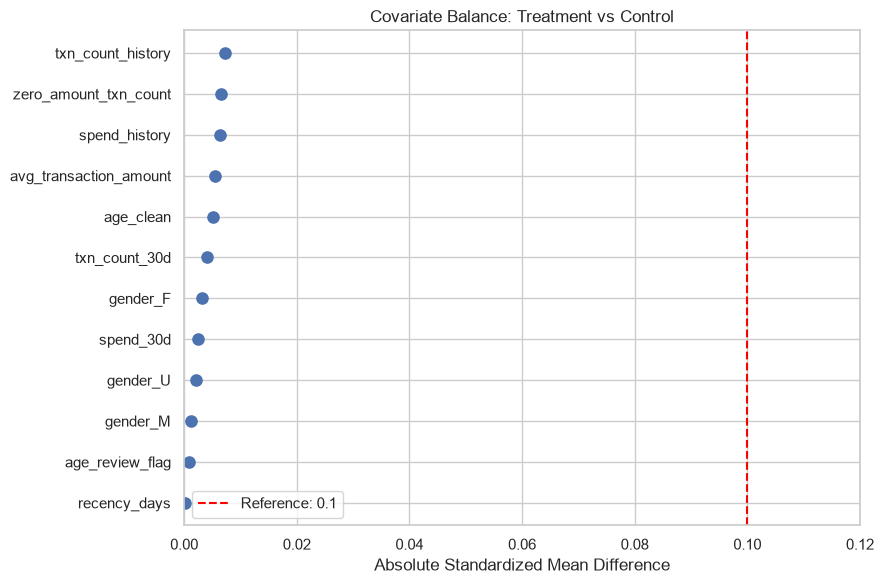

In [28]:
plot_data = full_balance.sort_values("abs_smd")

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    plot_data["abs_smd"],
    plot_data.index,
    s=65
)

ax.axvline(
    0.1,
    color="red",
    linestyle="--",
    label="Reference: 0.1"
)

ax.set_xlim(
    0,
    max(0.12, plot_data["abs_smd"].max() * 1.2)
)
ax.set_xlabel("Absolute Standardized Mean Difference")
ax.set_title("Covariate Balance: Treatment vs Control")
ax.legend()

plt.tight_layout()
plt.show()

### 完整特征平衡检查结论

本次比较覆盖对照组 100,058 名客户和处理组 99,981 名客户，纳入年龄、年龄复核标记、性别，以及模型使用的历史与近期交易行为特征。

所有被检查特征的绝对标准化均值差异（SMD）均小于 0.01。最大值出现在历史交易次数，为 0.0073，低于常用的 0.1 经验参考线。这表明两组在已检查特征的均值或类别比例上非常接近。

清洗年龄的非缺失样本量分别为 99,775 和 99,694。共 570 名客户的异常年龄被设为缺失，但客户本身未被删除；年龄复核标记的组间差异也较小。

该结果支持已观测特征上的均值平衡，但不证明完整分布一致，也不能证明随机分配或排除未观测混杂。处理分配机制仍需来源资料支持。

## 10. 沿用原客户划分与保存数据


本节读取独立保存的 data/splits/assignments.csv 和 metadata.json，校验文件内容、客户唯一性、覆盖范围、标签和内部顺序，再从当前特征表恢复原来的 60%／20%／20% 划分。名单由已有数据集一次性导出；无需保留旧特征文件，也不重新随机划分。


In [29]:
from src.splits import restore_splits
import pandas as pd

# 固定清单仅记录原客户名单、顺序与标签；特征由本次原始数据重新构建。
# 不依赖已有 data/processed 文件，也不重新随机划分。
restored_splits = restore_splits(feature_table, "data/splits")
train_df = restored_splits["train"]
valid_df = restored_splits["validation"]
test_df = restored_splits["test"]

split_summary = pd.DataFrame([
    {
        "dataset": name,
        "customers": len(frame),
        "treatment_share": frame["treatment_flg"].mean()
    }
    for name, frame in restored_splits.items()
])
display(split_summary)
print("固定划分校验通过：客户无交叉，覆盖范围、顺序及标签一致。")
print("当前特征已按原名单恢复；无需已有 processed 文件。")

from src.causal_robustness import validate_splits
validate_splits(train_df, valid_df, test_df)


,dataset,customers,treatment_share
0,train,120023,0.499804
1,validation,40008,0.499825
2,test,40008,0.499800


固定划分校验通过：客户无交叉，覆盖范围、顺序及标签一致。
当前特征已按原名单恢复；无需已有 processed 文件。


原划分按处理标记分层。训练集用于拟合预处理与模型；验证集用于模型诊断和策略比较；测试集不参与模型拟合。测试结果此前已经查看，后来新增的比较须标注为探索性分析。


### 10.1 训练集特征分布


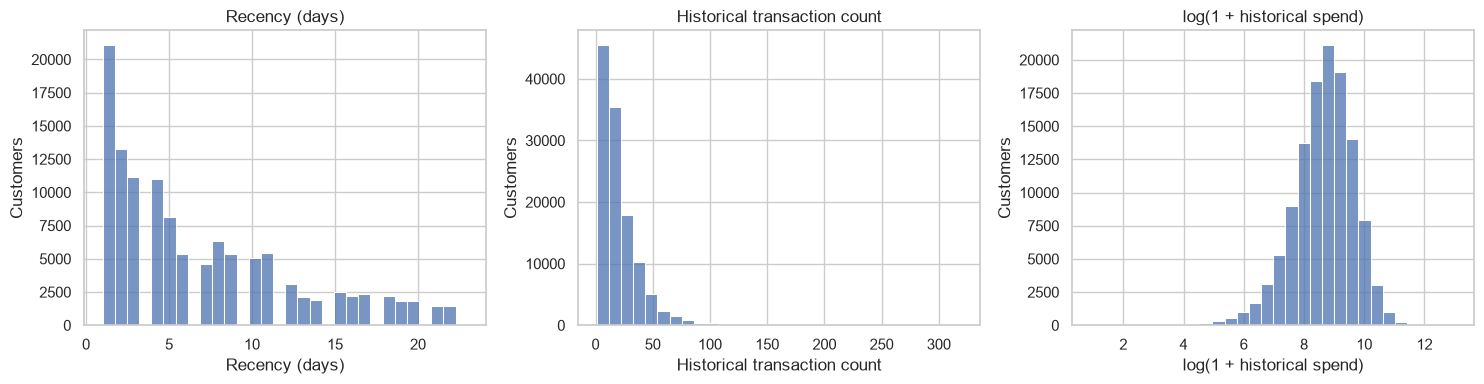

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plot_specs = [
    ("recency_days", "Recency (days)", False),
    ("txn_count_history", "Historical transaction count", False),
    ("spend_history", "log(1 + historical spend)", True)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (column, label, use_log) in zip(axes, plot_specs):
    values = train_df[column].dropna()

    if use_log:
        values = np.log1p(values)

    sns.histplot(x=values, bins=30, ax=ax)
    ax.set_xlabel(label)
    ax.set_ylabel("Customers")
    ax.set_title(label)

plt.tight_layout()
plt.show()

消费金额图使用 log(1 + 金额)，便于看清长尾分布；这一步只改变画图时的展示，没有修改原始特征。

### 10.2 保存处理后的数据


In [31]:
from pathlib import Path

Path("data/processed").mkdir(parents=True, exist_ok=True)

for name, frame in {
    "train": train_df,
    "validation": valid_df,
    "test": test_df
}.items():
    con.register("split_to_save", frame)

    con.execute(f"""
        COPY split_to_save
        TO 'data/processed/{name}.parquet'
        (FORMAT PARQUET)
    """)

print("三个数据集已保存")

三个数据集已保存
